# EN4554 Assignment 2: CNNs (Task 2 of 4: Optimizers)

## Setup (same as Task 1, but images keep their 3x32x32 shape for the CNN)

In [1]:
import copy, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)

def set_seed(s=0):
    torch.manual_seed(s); np.random.seed(s); torch.cuda.manual_seed_all(s)
set_seed(0)

full = datasets.CIFAR10('./data', train=True, download=True)   # test set not used here
X = torch.tensor(full.data).float().div(255).permute(0, 3, 1, 2)
y = torch.tensor(full.targets)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(0))
tr, va = perm[:45000], perm[45000:]
Xtr, ytr, Xva, yva = X[tr], y[tr], X[va], y[va]

mean = Xtr.mean((0, 2, 3), keepdim=True)      # training statistics only
std  = Xtr.std((0, 2, 3), keepdim=True)
Xtr, Xva = ((Xtr - mean) / std).to(device), ((Xva - mean) / std).to(device)
ytr, yva = ytr.to(device), yva.to(device)
print(Xtr.shape, Xva.shape)

Using device: cuda
torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32])


## Task 2(a): SGD with momentum and Adam as `torch.optim.Optimizer` subclasses
- **SGD with momentum:** `buf = momentum * buf + grad`, then `p -= lr * buf` (with `momentum=0` this is plain SGD).
- **Adam:** `m = b1*m + (1-b1)*g`, `v = b2*v + (1-b2)*g^2`, bias-corrected `m_hat = m/(1-b1^t)`, `v_hat = v/(1-b2^t)`, then `p -= lr * m_hat / (sqrt(v_hat) + eps)`.

In [3]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if 'buf' not in state:
                    state['buf'] = p.grad.clone()                  # first step: buf = grad
                else:
                    state['buf'].mul_(group['momentum']).add_(p.grad)
                p.add_(state['buf'], alpha=-group['lr'])

In [4]:
class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            b1, b2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if not state:
                    state['t'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)
                state['t'] += 1
                state['m'].mul_(b1).add_(p.grad, alpha=1 - b1)
                state['v'].mul_(b2).addcmul_(p.grad, p.grad, value=1 - b2)
                m_hat = state['m'] / (1 - b1 ** state['t'])        # bias correction
                v_hat = state['v'] / (1 - b2 ** state['t'])
                p.addcdiv_(m_hat, v_hat.sqrt() + group['eps'], value=-group['lr'])

In [5]:
# Compare with the built-in optimisers: same start, same data, 50 steps, float64
def max_param_diff(my_cls, ref_cls, **kw):
    torch.manual_seed(0)
    m1 = nn.Sequential(nn.Linear(10, 16), nn.ReLU(), nn.Linear(16, 3)).double()
    m2 = copy.deepcopy(m1)
    o1, o2 = my_cls(m1.parameters(), **kw), ref_cls(m2.parameters(), **kw)
    x, t = torch.randn(32, 10).double(), torch.randint(0, 3, (32,))
    for _ in range(50):
        for m, o in ((m1, o1), (m2, o2)):
            o.zero_grad()
            F.cross_entropy(m(x), t).backward()
            o.step()
    p1, p2 = list(m1.parameters()), list(m2.parameters())
    same = all(torch.allclose(a, b, atol=1e-10) for a, b in zip(p1, p2))
    return max((a - b).abs().max().item() for a, b in zip(p1, p2)), same



In [6]:
print('SGD (momentum 0.9):', max_param_diff(MySGD, torch.optim.SGD, lr=0.05, momentum=0.9))
print('SGD (no momentum)  :', max_param_diff(MySGD, torch.optim.SGD, lr=0.05, momentum=0.0))
print('Adam               :', max_param_diff(MyAdam, torch.optim.Adam, lr=0.01))

SGD (momentum 0.9): (0.0, True)
SGD (no momentum)  : (0.0, True)
Adam               : (2.220446049250313e-16, True)



| Optimizer            | Maximum parameter difference | Result |
| -------------------- | ---------------------------- | ------ |
| SGD with momentum    | 0.0                          | Pass   |
| SGD without momentum | 0.0                          | Pass   |
| Adam                 | \\(2.22 \times 10^{-16}\\)   | Pass   |


The custom SGD optimizer produces exactly the same parameters as PyTorch's built-in SGD, both with and without momentum. The custom Adam optimizer also matches PyTorch's implementation, with a maximum difference of approximately \\(2.22 \times 10^{-16}\\), which is negligible and attributable to floating-point precision.

So, The results verify that both custom optimizers correctly implement their update rules, including momentum for SGD and bias correction for Adam.



## Task 2(b): Trajectories on f(x, y) = 0.5 (x^2 + 50 y^2)
The contours are very elongated: curvature is 1 along x and 50 along y (condition number 50).
The gradient is (x, 50y). All three optimisers start at (10, 1) and take 100 steps.

In [7]:
def f(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def run(make_opt, steps=100, start=(10.0, 1.0)):
    p = torch.tensor(start, requires_grad=True)
    opt = make_opt([p])
    path = [p.detach().numpy().copy()]
    for _ in range(steps):
        opt.zero_grad()
        f(p).backward()
        opt.step()
        path.append(p.detach().numpy().copy())
    return np.array(path)

In [8]:
paths = {
    'SGD (lr=0.035)':           run(lambda ps: MySGD(ps, lr=0.035)),
    'SGD momentum (lr=0.02)':   run(lambda ps: MySGD(ps, lr=0.02, momentum=0.9)),
    'Adam (lr=0.3)':            run(lambda ps: MyAdam(ps, lr=0.3)),
}

gx, gy = np.meshgrid(np.linspace(-12, 12, 300), np.linspace(-2, 2, 300))
gz = 0.5 * (gx ** 2 + 50 * gy ** 2)


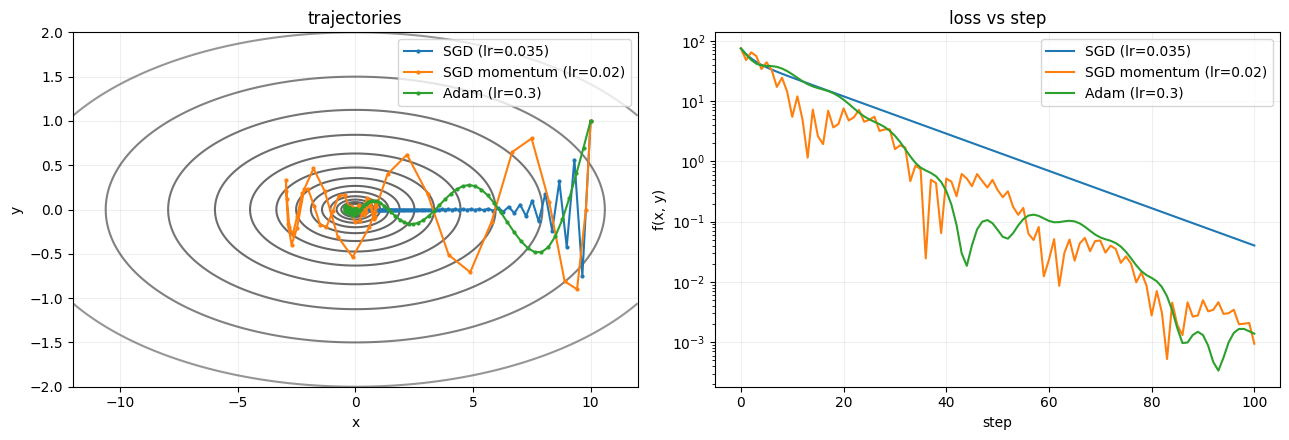

Optimizer                          Final x       Final y      Final loss
------------------------------------------------------------------------
SGD (lr=0.035)                    0.283616      0.000000    4.021915e-02
SGD momentum (lr=0.02)            0.042281      0.001350    9.394117e-04
Adam (lr=0.3)                     0.051310     -0.001642    1.383781e-03


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].contour(gx, gy, gz, levels=np.logspace(-1, 2.5, 15), cmap='gray', alpha=0.6)

for name, pth in paths.items():
    ax[0].plot(pth[:, 0], pth[:, 1], marker='.', ms=4, label=name)

ax[0].set_xlabel('x');
ax[0].grid(alpha=0.2)
ax[0].set_ylabel('y');
ax[0].legend();
ax[0].set_title('trajectories')


for name, pth in paths.items():
    vals = 0.5 * (pth[:, 0] ** 2 + 50 * pth[:, 1] ** 2)
    ax[1].semilogy(vals, label=name)

ax[1].set_xlabel('step');
ax[1].grid(alpha=0.2)
ax[1].set_ylabel('f(x, y)');
ax[1].legend();
ax[1].set_title('loss vs step')
plt.tight_layout();

plt.show()

print(f"{'Optimizer':<28}{'Final x':>14}{'Final y':>14}{'Final loss':>16}")
print("-" * 72)

for name, pth in paths.items():
    x_final, y_final = pth[-1]
    final_loss = 0.5 * (x_final**2 + 50 * y_final**2)

    print(f"{name:<28}{x_final:>14.6f}{y_final:>14.6f}{final_loss:>16.6e}")

| Optimizer         | Final loss | Observation                    |
| ----------------- | ---------- | ------------------------------ |
| SGD               | 0.040219   | Slowest convergence            |
| SGD with momentum | 0.000939   | Lowest final loss              |
| Adam              | 0.001384   | Converges close to the minimum |

The minimum of the function is at \\((0,0)\\), where the loss is zero. Standard SGD makes slower progress because the function has different curvature along the \\(x\\) and \\(y\\) directions. Momentum uses accumulated gradients to accelerate progress and achieves the lowest loss in this experiment. Adam adapts the learning rate for each coordinate and also converges close to the minimum.

So, For these learning rates and 100 steps, SGD with momentum achieves the lowest final loss. This does not mean it is always better than Adam, because the result depends on the learning rates, momentum, and number of steps.

## Task 2(c): Small CNN, three optimisers x three learning rates
Small CNN with no batch norm, so learning-rate sensitivity is visible. 5 epochs per run, batch size 128, same seed for every run.
Learning rates are spaced by 10x around each optimiser's usual range.

In [13]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 16x16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 8x8
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))   # 4x4
        self.fc = nn.Linear(128 * 4 * 4, 10)
    def forward(self, x):
        return self.fc(self.features(x).flatten(1))

In [14]:
@torch.no_grad()
def evaluate(model, X, t):
    model.eval()
    correct = sum((model(X[i:i+1000]).argmax(1) == t[i:i+1000]).sum().item()
                  for i in range(0, len(X), 1000))
    return correct / len(X)

def train_cnn(make_opt, epochs=5, bs=128):
    set_seed(0)
    model = SmallCNN().to(device)
    opt = make_opt(model.parameters())
    train_losses, val_accs = [], []
    for ep in range(epochs):
        model.train()
        idx = torch.randperm(len(Xtr), device=device)
        total, n = 0.0, 0
        for i in range(0, len(idx), bs):
            b = idx[i:i+bs]
            loss = F.cross_entropy(model(Xtr[b]), ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(b); n += len(b)
        train_losses.append(total / n)
        val_accs.append(evaluate(model, Xva, yva))
        if np.isnan(train_losses[-1]):          # diverged: stop early
            break
    return train_losses, val_accs

In [15]:
configs = {
    'SGD':          (lambda lr: (lambda ps: MySGD(ps, lr=lr)),               [0.003, 0.03, 0.3]),
    'SGD momentum': (lambda lr: (lambda ps: MySGD(ps, lr=lr, momentum=0.9)), [0.001, 0.01, 0.1]),
    'Adam':         (lambda lr: (lambda ps: MyAdam(ps, lr=lr)),              [1e-4, 1e-3, 1e-2]),
}

results = {}                                     # (name, lr) -> (train_losses, val_accs)

for name, (maker, lrs) in configs.items():
    for lr in lrs:
        results[(name, lr)] = train_cnn(maker(lr))
        print(f"{name:13s} lr={lr:<7g} final train loss {results[(name, lr)][0][-1]:.3f}  "
              f"val acc {results[(name, lr)][1][-1]:.4f}")

SGD           lr=0.003   final train loss 1.787  val acc 0.3818
SGD           lr=0.03    final train loss 1.079  val acc 0.6292
SGD           lr=0.3     final train loss 0.885  val acc 0.6528
SGD momentum  lr=0.001   final train loss 1.363  val acc 0.5192
SGD momentum  lr=0.01    final train loss 0.743  val acc 0.7160
SGD momentum  lr=0.1     final train loss 1.229  val acc 0.5660
Adam          lr=0.0001  final train loss 1.230  val acc 0.5684
Adam          lr=0.001   final train loss 0.669  val acc 0.7270
Adam          lr=0.01    final train loss 1.242  val acc 0.5462


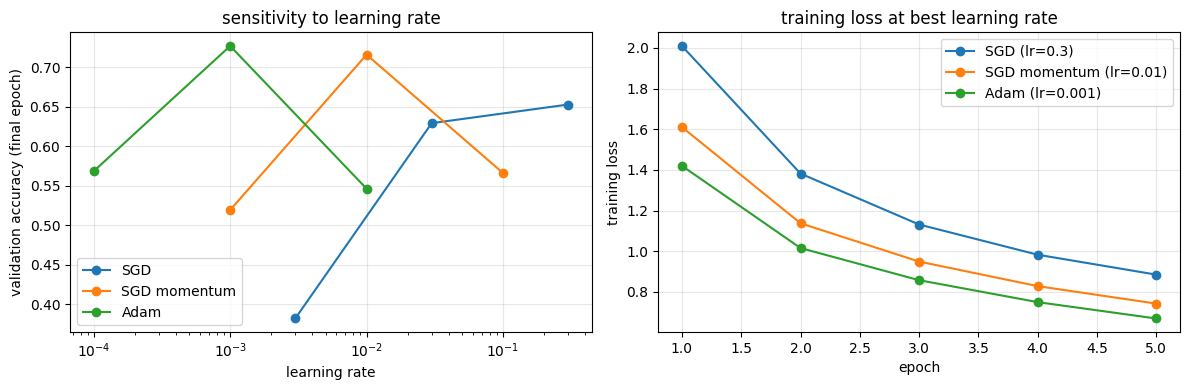


Best results for each optimizer
---------------------------------------------------------------------------
Optimizer            Best LR      Val Accuracy    Final Train Loss
---------------------------------------------------------------------------
SGD                      0.3         65.2800%              0.8851
SGD momentum            0.01         71.6000%              0.7427
Adam                   0.001         72.7000%              0.6695


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
best = {}

for name, (maker, lrs) in configs.items():
    accs = [results[(name, lr)][1][-1] for lr in lrs]
    ax[0].semilogx(lrs, accs, marker='o', label=name)
    best[name] = lrs[int(np.argmax(accs))]

ax[0].set_xlabel('learning rate');
ax[0].set_ylabel('validation accuracy (final epoch)')
ax[0].legend();
ax[0].grid(alpha=0.3);
ax[0].set_title('sensitivity to learning rate')

for name, lr in best.items():
    ax[1].plot(range(1, 6), results[(name, lr)][0], marker='o', label=f'{name} (lr={lr:g})')

ax[1].set_xlabel('epoch');
ax[1].set_ylabel('training loss')
ax[1].legend();
ax[1].grid(alpha=0.3);
ax[1].set_title('training loss at best learning rate')
plt.tight_layout();
plt.show()

print("\nBest results for each optimizer")
print("-" * 75)
print(f"{'Optimizer':<16}{'Best LR':>12}{'Val Accuracy':>18}{'Final Train Loss':>20}")
print("-" * 75)

for name, lr in best.items():
    train_losses, val_accs = results[(name, lr)]

    print(
        f"{name:<16}"
        f"{lr:>12.4g}"
        f"{val_accs[-1]:>17.4%}"
        f"{train_losses[-1]:>20.4f}"
    )

The results show that all three optimizers are sensitive to the learning rate.

- SGD: Validation accuracy improves from 38.18% to 65.28% as the learning rate increases from 0.003 to 0.3. The highest tested learning rate performs best among the three SGD settings.
- SGD with momentum: The learning rate of 0.01 achieves 71.60% validation accuracy. Increasing it to 0.1 reduces accuracy to 56.60%, showing that a learning rate that is too high can negatively affect training.
- Adam: The learning rate of 0.001 achieves the highest validation accuracy of 72.70% and the lowest final training loss of 0.6695 among the selected best settings. Both smaller and larger learning rates perform worse.

So, based on that Adam performs best among the tested configurations, with SGD with momentum close behind. Adam and momentum SGD perform better than plain SGD in this experiment, although the comparison depends on the learning rates and training setup. These results suggest that selecting a suitable learning rate is important for both convergence and validation performance.